## 0. Persiapan Lingkungan dan Dataset

In [1]:
# ==== IDENTITAS (ubah sesuai data Anda) ====
NAMA  = "Khansa Nisrina"
NIM   = "2330511089"          # SEED = 4 digit terakhir NIM
KELAS = "TI-7B"

import os, sys
SEED = int(NIM[-4:])
DI_COLAB = "google.colab" in sys.modules
ROOT = f"/content/simuteh-{NIM}" if DI_COLAB else os.path.abspath(f"simuteh-{NIM}")
for sub in ["data", "notebook", "src", "hasil", "laporan"]:
    os.makedirs(os.path.join(ROOT, sub), exist_ok=True)
os.chdir(ROOT)
print("Folder kerja :", ROOT)
print("SEED         :", SEED)

Folder kerja : /content/simuteh-2330511089
SEED         : 1089


In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
%%writefile src/buat_dataset_sintetis.py
"""
buat_dataset_sintetis.py
Membangkitkan dataset citra sintetis daun teh untuk studi kasus SIMUTEH.
Setiap mahasiswa memakai SEED = 4 digit terakhir NIM sehingga datanya berbeda.

Keluaran (folder data/sintetis/):
  citra/    citra berwarna hasil "pemotretan" (dengan gangguan cahaya dan derau)
  bersih/   citra yang sama tanpa gangguan (acuan mutu)
  mask_daun/    mask area daun (255 = daun)
  mask_bercak/  mask area bercak penyakit (255 = bercak)
  label.csv     nama_file, kelas, kondisi_cahaya, persen_bercak
"""
import os
import csv
import cv2
import numpy as np

SEED = 1089          # GANTI dengan 4 digit terakhir NIM Anda
N_PER_KELAS = 20     # 20 citra x 3 kelas = 60 citra
H, W = 480, 640
KELAS = ["sehat", "ringan", "berat"]
KONDISI = ["normal", "gelap", "terang", "kontras_rendah", "bayangan"]
OUT = os.path.join("data", "sintetis")

rng = np.random.default_rng(SEED)


def gambar_daun(img, mask):
    """Menggambar satu helai daun berbentuk elips beserta tulang daunnya."""
    cx = int(rng.integers(260, 380))
    cy = int(rng.integers(200, 280))
    ax = int(rng.integers(190, 240))
    ay = int(rng.integers(95, 125))
    sudut = float(rng.uniform(-25, 25))
    hijau = np.array([rng.integers(35, 60), rng.integers(120, 150),
                      rng.integers(45, 75)])               # BGR
    cv2.ellipse(img, (cx, cy), (ax, ay), sudut, 0, 360, hijau.tolist(), -1)
    cv2.ellipse(mask, (cx, cy), (ax, ay), sudut, 0, 360, 255, -1)
    # tulang daun utama dan cabang
    t = np.deg2rad(sudut)
    p1 = (int(cx - ax * np.cos(t)), int(cy - ax * np.sin(t)))
    p2 = (int(cx + ax * np.cos(t)), int(cy + ax * np.sin(t)))
    tulang = (hijau * 1.35).clip(0, 255).tolist()
    cv2.line(img, p1, p2, tulang, 3)
    for k in np.linspace(-0.7, 0.7, 6):
        bx, by = cx + k * ax * np.cos(t), cy + k * ax * np.sin(t)
        for arah in (-1, 1):
            ex = bx + 0.35 * ax * np.cos(t + arah * 1.0)
            ey = by + 0.35 * ax * np.sin(t + arah * 1.0)
            cv2.line(img, (int(bx), int(by)), (int(ex), int(ey)), tulang, 1)
    return mask


def gambar_bercak(img, mask_daun, mask_bercak, kelas):
    """Menambahkan bercak cacar daun (pucat kekuningan, tepi kecokelatan)."""
    if kelas == "sehat":
        return
    n = int(rng.integers(1, 4)) if kelas == "ringan" else int(rng.integers(6, 13))
    r_min, r_maks = (3, 7) if kelas == "ringan" else (5, 14)
    ys, xs = np.where(mask_daun > 0)
    for _ in range(n):
        i = int(rng.integers(0, len(xs)))
        r = int(rng.integers(r_min, r_maks + 1))
        pusat = (int(xs[i]), int(ys[i]))
        warna = [int(rng.integers(70, 100)), int(rng.integers(165, 190)),
                 int(rng.integers(185, 210))]               # BGR pucat
        cv2.circle(img, pusat, r + 2, (40, 80, 110), -1)    # tepi cokelat
        cv2.circle(img, pusat, r, warna, -1)
        cv2.circle(mask_bercak, pusat, r + 2, 255, -1)
    mask_bercak &= mask_daun                                # bercak hanya di daun


def ganggu_cahaya(img, kondisi):
    """Mensimulasikan kondisi pemotretan di lapangan."""
    f = img.astype(np.float32)
    if kondisi == "gelap":
        f = 255 * (f / 255) ** 2.0
    elif kondisi == "terang":
        f = 255 * (f / 255) ** 0.45
    elif kondisi == "kontras_rendah":
        f = 0.35 * f + 95
    elif kondisi == "bayangan":
        gx = np.linspace(1.15, 0.30, W, dtype=np.float32)   # separuh teduh
        f = f * gx[None, :, None]
    sigma = float(rng.uniform(6, 14))
    f = f + rng.normal(0, sigma, f.shape)                   # derau sensor
    return np.clip(f, 0, 255).astype(np.uint8)


def main():
    for sub in ["citra", "bersih", "mask_daun", "mask_bercak"]:
        os.makedirs(os.path.join(OUT, sub), exist_ok=True)
    baris = []
    nomor = 0
    for kelas in KELAS:
        for j in range(N_PER_KELAS):
            nomor += 1
            latar = np.array([rng.integers(150, 190), rng.integers(170, 205),
                              rng.integers(185, 215)])      # nampan anyaman
            img = np.ones((H, W, 3), np.uint8) * latar.astype(np.uint8)
            img = cv2.add(img, rng.integers(0, 12, (H, W, 3)).astype(np.uint8))
            m_daun = np.zeros((H, W), np.uint8)
            m_bercak = np.zeros((H, W), np.uint8)
            gambar_daun(img, m_daun)
            gambar_bercak(img, m_daun, m_bercak, kelas)
            bersih = cv2.GaussianBlur(img, (3, 3), 0.8)
            kondisi = KONDISI[j % len(KONDISI)]
            citra = ganggu_cahaya(bersih, kondisi)
            nama = f"teh_{nomor:03d}.png"
            cv2.imwrite(os.path.join(OUT, "citra", nama), citra)
            cv2.imwrite(os.path.join(OUT, "bersih", nama), bersih)
            cv2.imwrite(os.path.join(OUT, "mask_daun", nama), m_daun)
            cv2.imwrite(os.path.join(OUT, "mask_bercak", nama), m_bercak)
            persen = 100 * (m_bercak > 0).sum() / max((m_daun > 0).sum(), 1)
            baris.append([nama, kelas, kondisi, round(persen, 2)])
    with open(os.path.join(OUT, "label.csv"), "w", newline="") as f:
        w = csv.writer(f)
        w.writerow(["nama_file", "kelas", "kondisi_cahaya", "persen_bercak"])
        w.writerows(baris)
    print(f"Selesai: {nomor} citra tersimpan di {OUT}")


if __name__ == "__main__":
    main()


Writing src/buat_dataset_sintetis.py


In [4]:
%%writefile src/utils_cv.py
"""utils_cv.py: fungsi bantu yang dipakai ulang sepanjang semester."""
import cv2
import numpy as np
import matplotlib.pyplot as plt


def baca(path):
    """Membaca citra dan langsung memberi pesan jelas bila gagal."""
    img = cv2.imread(path)
    if img is None:
        raise FileNotFoundError(f"Citra tidak ditemukan: {path}")
    return img


def tampil(daftar, judul, baris=1, ukuran=(14, 4)):
    """Menampilkan beberapa citra berdampingan. Citra 3 kanal dianggap BGR."""
    kolom = int(np.ceil(len(daftar) / baris))
    plt.figure(figsize=ukuran)
    for i, (im, jd) in enumerate(zip(daftar, judul)):
        plt.subplot(baris, kolom, i + 1)
        if im.ndim == 3:
            plt.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
        else:
            plt.imshow(im, cmap="gray", vmin=0, vmax=255)
        plt.title(jd)
        plt.axis("off")
    plt.tight_layout()


def kontras_bercak(kanal, mask_daun, mask_bercak):
    """KB = |rerata bercak - rerata daun sehat| / simpangan baku daun sehat.
    Makin besar KB, makin mudah bercak dipisahkan dari daun sehat."""
    k = kanal.astype(np.float64)
    sehat = (mask_daun > 0) & (mask_bercak == 0)
    bercak = mask_bercak > 0
    if bercak.sum() == 0:
        return float("nan")
    return abs(k[bercak].mean() - k[sehat].mean()) / (k[sehat].std() + 1e-6)


def statistik(gray):
    """Ringkasan statistik intensitas untuk mendiagnosis mutu citra."""
    return {"rerata": round(float(gray.mean()), 1),
            "simpangan_baku": round(float(gray.std()), 1),
            "min": int(gray.min()), "maks": int(gray.max()),
            "persen_gelap": round(100 * float((gray < 50).mean()), 1),
            "persen_terang": round(100 * float((gray > 205).mean()), 1)}


Writing src/utils_cv.py


In [5]:
# Pasang SEED sesuai NIM, bangkitkan dataset, lalu pindah ke folder notebook/
import re, subprocess
kode = open("src/buat_dataset_sintetis.py").read()
kode = re.sub(r"^SEED = \d+", f"SEED = {SEED}", kode, count=1, flags=re.M)
open("src/buat_dataset_sintetis.py", "w").write(kode)
keluaran = subprocess.run([sys.executable, "src/buat_dataset_sintetis.py"],
                          capture_output=True, text=True)
print(keluaran.stdout, keluaran.stderr)

# requirements.txt untuk reprodusibilitas
import cv2, numpy, pandas, matplotlib, skimage, PIL
with open("requirements.txt", "w") as f:
    for nm, m in [("opencv-python", cv2), ("numpy", numpy), ("pandas", pandas),
                  ("matplotlib", matplotlib), ("scikit-image", skimage), ("pillow", PIL)]:
        f.write(f"{nm}=={m.__version__}\n")
print(open("requirements.txt").read())

os.chdir(os.path.join(ROOT, "notebook"))   # semua jalur selanjutnya diawali ../

Selesai: 60 citra tersimpan di data/sintetis
 
opencv-python==5.0.0
numpy==2.4.6
pandas==2.2.3
matplotlib==3.10.0
scikit-image==0.25.2
pillow==11.3.0



In [6]:
# Pustaka dan fungsi bantu yang dipakai di seluruh notebook
sys.path.append("../src")
import time, json
import cv2, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from utils_cv import baca, tampil, kontras_bercak, statistik

pd.set_option("display.width", 140)
plt.rcParams["figure.dpi"] = 90

def muat(nama, folder="citra"):
    """Mengembalikan (citra BGR, mask daun, mask bercak) untuk satu nama berkas."""
    img = baca(f"../data/sintetis/{folder}/{nama}")
    md = cv2.imread(f"../data/sintetis/mask_daun/{nama}", 0)
    mb = cv2.imread(f"../data/sintetis/mask_bercak/{nama}", 0)
    return img, md, mb

def selisih_rerata(kanal, mask_daun, mask_bercak):
    """dI = |rerata bercak - rerata daun sehat| (satuan intensitas)."""
    k = kanal.astype(float)
    sehat = (mask_daun > 0) & (mask_bercak == 0)
    return abs(k[mask_bercak > 0].mean() - k[sehat].mean())

label = pd.read_csv("../data/sintetis/label.csv")
print(label.groupby(["kelas", "kondisi_cahaya"]).size().unstack())
print(label.groupby("kelas").persen_bercak.describe().round(2))

kondisi_cahaya  bayangan  gelap  kontras_rendah  normal  terang
kelas                                                          
berat                  4      4               4       4       4
ringan                 4      4               4       4       4
sehat                  4      4               4       4       4
        count  mean   std   min   25%   50%   75%   max
kelas                                                  
berat    20.0  4.67  1.27  2.69  3.52  4.90  5.71  6.82
ringan   20.0  0.43  0.21  0.10  0.30  0.44  0.62  0.78
sehat    20.0  0.00  0.00  0.00  0.00  0.00  0.00  0.00


## Bagian 4. Konvolusi dan Penapisan Spasial
### Langkah 4.1 Lembar hitung (verifikasi dengan kode)

In [7]:
P = np.array([[52, 55, 61, 58], [59, 255, 64, 60], [62, 60, 0, 57], [58, 61, 59, 63]], float)
Kg = np.array([[1, 2, 1], [2, 4, 2], [1, 2, 1]]) / 16
rer, gau, med = np.zeros((2, 2)), np.zeros((2, 2)), np.zeros((2, 2))
for y in range(2):
    for x in range(2):
        w = P[y:y+3, x:x+3]
        rer[y, x], gau[y, x], med[y, x] = w.mean(), (w * Kg).sum(), np.median(w)
print("a) rerata:\n", rer.round(2), "\n   Gaussian:\n", gau.round(2), "\n   median:\n", med)
Q = np.array([[70, 72, 75], [74, 120, 78], [73, 76, 79]])
Kt = np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]])
print("b) kernel tajam:", (Q * Kt).sum(), "-> setelah clipping:", min((Q * Kt).sum(), 255))
baris_ = np.array([12, 30, 45, 70])
for mode, pd_ in [("zero", np.pad(baris_, 1)), ("replicate", np.pad(baris_, 1, mode="edge")),
                  ("reflect101", np.pad(baris_, 1, mode="reflect"))]:
    print(f"c) {mode:10s}: {pd_.tolist()} -> rerata 1x3 piksel pertama = {pd_[:3].mean():.2f}")

a) rerata:
 [[74.22 74.44]
 [75.33 75.44]] 
   Gaussian:
 [[104.44  77.38]
 [ 77.25  57.44]] 
   median:
 [[60. 60.]
 [60. 60.]]
b) kernel tajam: 300 -> setelah clipping: 255
c) zero      : [0, 12, 30, 45, 70, 0] -> rerata 1x3 piksel pertama = 14.00
c) replicate : [12, 12, 30, 45, 70, 70] -> rerata 1x3 piksel pertama = 18.00
c) reflect101: [30, 12, 30, 45, 70, 45] -> rerata 1x3 piksel pertama = 24.00


### Jawaban Lembar Hitung Bagian 4

| Penapis | (1,1) | (1,2) | (2,1) | (2,2) |
|---|---|---|---|---|
| Jumlah jendela | 668 | 670 | 678 | 679 |
| Rerata 3 x 3 | 74,22 (74) | 74,44 (74) | 75,33 (75) | 75,44 (75) |
| Gaussian 1/16 | 104,44 (104) | 77,38 (77) | 77,25 (77) | 57,44 (57) |
| Median 3 x 3 | 60 | 60 | 60 | 60 |

* **b)** 5 x 120 - (72 + 74 + 78 + 76) = 600 - 300 = 300, dipotong menjadi **255**.
* **c)** Zero padding [0,12,30,45,70,0] menghasilkan **14**; replicate [12,12,30,45,70,70] menghasilkan **18**; reflect101 [30,12,30,45,70,45] menghasilkan **24**.

### Kode 4.1 Verifikasi konvolusi manual

rerata: selisih manual vs filter2D=0, sejati vs filter2D=0, waktu manual=2.003 s, filter2D=0.01179 s, lebih cepat 170x
asimetris: selisih manual vs filter2D=0, sejati vs filter2D=255, waktu manual=1.990 s, filter2D=0.00036 s, lebih cepat 5,602x


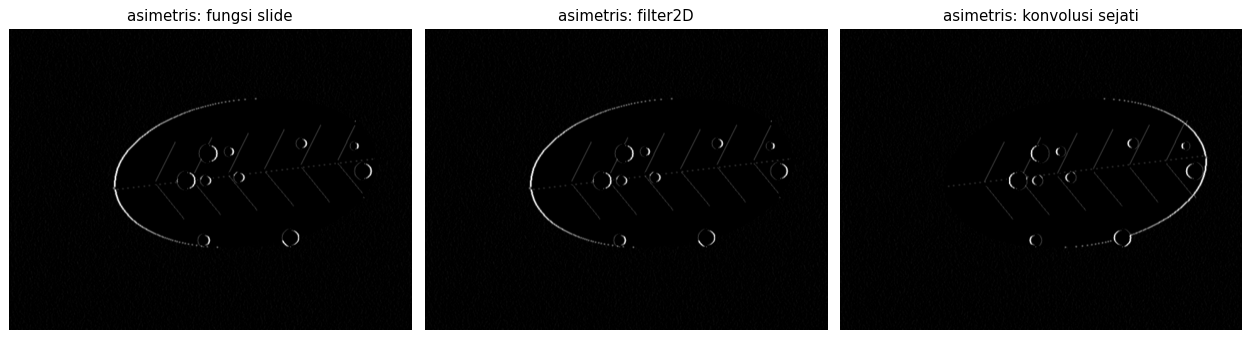

In [8]:
def konvolusi(img, k):            # fungsi dari slide P4
    kh, kw = k.shape; ph, pw = kh // 2, kw // 2
    pad = np.pad(img.astype(float), ((ph, ph), (pw, pw)), mode="edge")
    out = np.zeros(img.shape)
    for y in range(img.shape[0]):
        for x in range(img.shape[1]):
            out[y, x] = np.sum(pad[y:y+kh, x:x+kw] * k)
    return np.clip(np.round(out), 0, 255).astype(np.uint8)

def konvolusi_sejati(img, k):     # kernel dibalik 180 derajat dahulu
    return konvolusi(img, np.flip(k))

nama = "teh_041.png"
bersih = cv2.cvtColor(baca(f"../data/sintetis/bersih/{nama}"), cv2.COLOR_BGR2GRAY)
_, md, mb = muat(nama)

for nm, k in {"rerata": np.ones((3, 3)) / 9,
              "asimetris": np.array([[1, 0, -1], [2, 0, -2], [1, 0, -1]], float)}.items():
    t0 = time.perf_counter(); a = konvolusi(bersih, k); t_manual = time.perf_counter() - t0
    t0 = time.perf_counter(); b_ = cv2.filter2D(bersih, -1, k, borderType=cv2.BORDER_REPLICATE)
    t_cv = time.perf_counter() - t0
    c = konvolusi_sejati(bersih, k)
    print(f"{nm}: selisih manual vs filter2D={np.abs(a.astype(int)-b_.astype(int)).max()}, "
          f"sejati vs filter2D={np.abs(c.astype(int)-b_.astype(int)).max()}, "
          f"waktu manual={t_manual:.3f} s, filter2D={t_cv:.5f} s, lebih cepat {t_manual/t_cv:,.0f}x")
tampil([a, b_, c], ["asimetris: fungsi slide", "asimetris: filter2D", "asimetris: konvolusi sejati"])
plt.show()

### Kode 4.2 Tabel penapis x derau x PSNR x waktu x KB

Ringkasan untuk laporan (derau Gaussian 20 dan garam-merica 4%)


PSNR_dB        waktu_ms              KB      
derau    gauss_20  sp_4% gauss_20  sp_4% gauss_20 sp_4%
penapis                                                
gauss_5     32.56  29.46     0.28   0.26     4.50  3.76
median_3    29.73  48.29     0.13   0.09     3.70  6.24
median_5    33.42  44.73     0.85   0.79     4.90  6.51
median_9    35.34  40.47    14.00  17.10     5.60  7.05
rerata_3    31.43  28.37     0.12   0.12     4.17  3.45
rerata_5    34.47  31.61     0.14   0.14     5.04  4.44
tanpa       22.11  19.18     0.00   0.00     1.79  1.34

Penapis dengan PSNR tertinggi per derau:


,derau,penapis,PSNR_dB,waktu_ms,KB
5,gauss_10,median_5,38.27,0.72,5.98
13,gauss_20,median_9,35.34,14.00,5.60
20,gauss_40,median_9,31.21,14.86,4.07
33,sp_10%,median_5,43.50,2.66,6.47
25,sp_4%,median_3,48.29,0.09,6.24


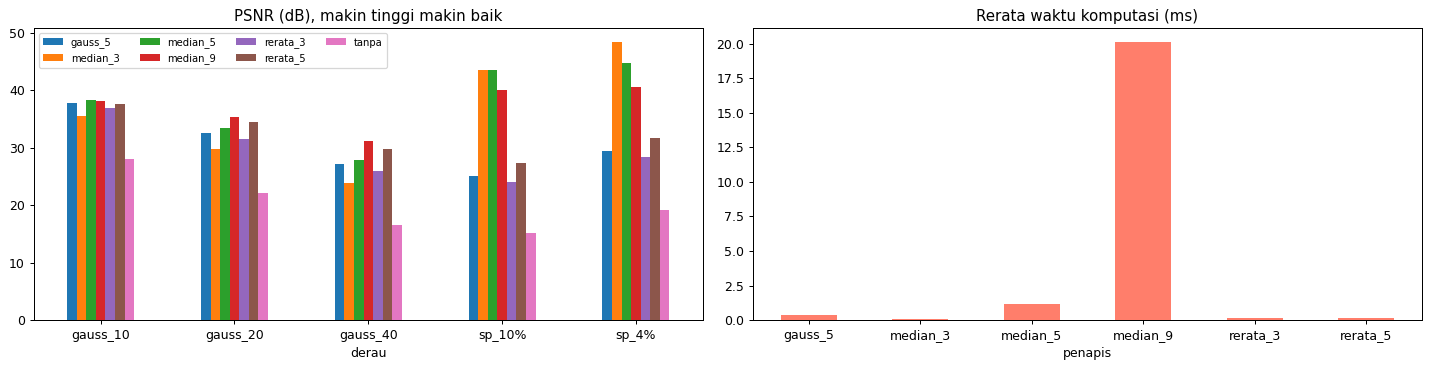

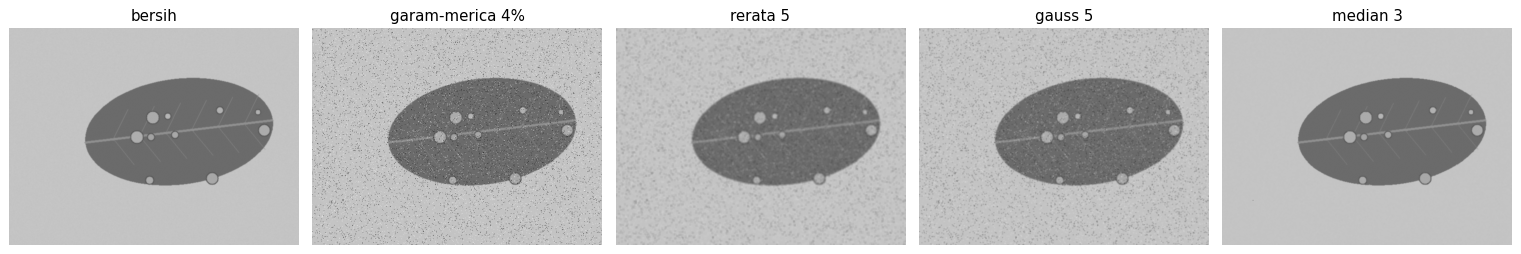

In [9]:
rng = np.random.default_rng(42)
def derau_gauss(img, sd):
    return np.clip(img + rng.normal(0, sd, img.shape), 0, 255).astype(np.uint8)
def derau_sp(img, p):
    out = img.copy(); m = rng.random(img.shape)
    out[m < p / 2] = 0; out[m > 1 - p / 2] = 255
    return out
def ukur_waktu(f, x, ulang=20):
    t = []
    for _ in range(ulang):
        t0 = time.perf_counter(); f(x); t.append(time.perf_counter() - t0)
    return 1000 * np.mean(t)

derau = {"gauss_10": derau_gauss(bersih, 10), "gauss_20": derau_gauss(bersih, 20),
         "gauss_40": derau_gauss(bersih, 40), "sp_4%": derau_sp(bersih, 0.04),
         "sp_10%": derau_sp(bersih, 0.10)}
penapis = {"rerata_3": lambda x: cv2.blur(x, (3, 3)), "rerata_5": lambda x: cv2.blur(x, (5, 5)),
           "gauss_5": lambda x: cv2.GaussianBlur(x, (5, 5), 1.0),
           "median_3": lambda x: cv2.medianBlur(x, 3), "median_5": lambda x: cv2.medianBlur(x, 5),
           "median_9": lambda x: cv2.medianBlur(x, 9)}
baris = []
for dn, d in derau.items():
    baris.append([dn, "tanpa", cv2.PSNR(bersih, d), 0.0, kontras_bercak(d, md, mb)])
    for pn, f_ in penapis.items():
        out = f_(d)
        baris.append([dn, pn, cv2.PSNR(bersih, out), ukur_waktu(f_, d), kontras_bercak(out, md, mb)])
tabel = pd.DataFrame(baris, columns=["derau", "penapis", "PSNR_dB", "waktu_ms", "KB"]).round(2)
tabel.to_csv("../hasil/b4_tabel_penapis.csv", index=False)

ringkas = tabel[tabel.derau.isin(["gauss_20", "sp_4%"])].pivot(index="penapis", columns="derau",
                                                                  values=["PSNR_dB", "waktu_ms", "KB"])
print("Ringkasan untuk laporan (derau Gaussian 20 dan garam-merica 4%)"); display(ringkas)
print("Penapis dengan PSNR tertinggi per derau:")
display(tabel[tabel.penapis != "tanpa"].loc[lambda t: t.groupby("derau").PSNR_dB.idxmax()])

fig, ax = plt.subplots(1, 2, figsize=(16, 4.2))
tabel.pivot(index="derau", columns="penapis", values="PSNR_dB").plot.bar(ax=ax[0], rot=0)
ax[0].set_title("PSNR (dB), makin tinggi makin baik"); ax[0].legend(fontsize=8, ncol=4)
tabel[tabel.penapis != "tanpa"].groupby("penapis").waktu_ms.mean().plot.bar(ax=ax[1], rot=0, color="#FF7E6B")
ax[1].set_title("Rerata waktu komputasi (ms)")
plt.tight_layout(); plt.savefig("../hasil/b4_grafik_penapis.png", bbox_inches="tight"); plt.show()
tampil([bersih, derau["sp_4%"], penapis["rerata_5"](derau["sp_4%"]), penapis["gauss_5"](derau["sp_4%"]),
        penapis["median_3"](derau["sp_4%"])], ["bersih", "garam-merica 4%", "rerata 5", "gauss 5", "median 3"],
       ukuran=(17, 3.4)); plt.show()

### Kode 4.3 Pengaruh ukuran kernel median pada bercak kecil

,dI,KB,dI_% dari asli
kernel,,,
1,29.67,4.73,100.0
3,29.95,4.85,101.0
5,28.78,4.72,97.0
9,22.66,4.23,76.4
15,9.64,2.52,32.5


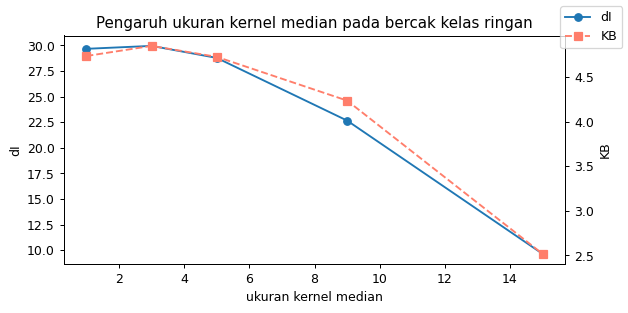

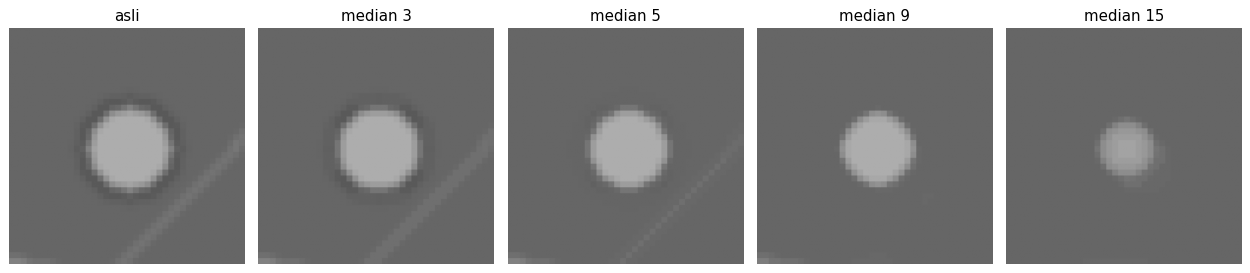

In [10]:
baris = []
for nm in label[label.kelas == "ringan"].nama_file:
    g_ = cv2.cvtColor(baca(f"../data/sintetis/bersih/{nm}"), cv2.COLOR_BGR2GRAY)
    _, md2, mb2 = muat(nm)
    for k in [1, 3, 5, 9, 15]:
        out = g_ if k == 1 else cv2.medianBlur(g_, k)
        baris.append([nm, k, selisih_rerata(out, md2, mb2), kontras_bercak(out, md2, mb2)])
hasil_median = pd.DataFrame(baris, columns=["nama", "kernel", "dI", "KB"])
rek = hasil_median.groupby("kernel")[["dI", "KB"]].mean()
rek["dI_% dari asli"] = (100 * rek.dI / rek.dI.iloc[0]).round(1)
display(rek.round(2))

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(rek.index, rek.dI, "o-", label="dI"); ax.set_xlabel("ukuran kernel median"); ax.set_ylabel("dI")
ax2 = ax.twinx(); ax2.plot(rek.index, rek.KB, "s--", color="#FF7E6B", label="KB"); ax2.set_ylabel("KB")
fig.legend(loc="upper right"); plt.title("Pengaruh ukuran kernel median pada bercak kelas ringan")
plt.tight_layout(); plt.savefig("../hasil/b4_median_bercak.png", bbox_inches="tight"); plt.show()

# perbesar satu bercak kecil
g_ = cv2.cvtColor(baca("../data/sintetis/bersih/teh_026.png"), cv2.COLOR_BGR2GRAY)
_, md2, mb2 = muat("teh_026.png")
n_lbl, lbl, st_, cen = cv2.connectedComponentsWithStats(mb2)
i_kecil = 1 + np.argmin(st_[1:, cv2.CC_STAT_AREA]); cx, cy = cen[i_kecil].astype(int)
crop = lambda x: cv2.resize(x[cy-20:cy+20, cx-20:cx+20], (160, 160), interpolation=cv2.INTER_NEAREST)
tampil([crop(g_)] + [crop(cv2.medianBlur(g_, k)) for k in [3, 5, 9, 15]],
       ["asli"] + [f"median {k}" for k in [3, 5, 9, 15]], ukuran=(14, 3))
plt.savefig("../hasil/b4_crop_bercak.png", bbox_inches="tight"); plt.show()

### Kode 4.4 Pengaruh urutan penajaman

In [11]:
def unsharp(x, k=1.0):
    blur = cv2.GaussianBlur(x, (5, 5), 1.0)
    return cv2.addWeighted(x, 1 + k, blur, -k, 0)

noisy = derau["gauss_20"]
latar = md == 0
baris = []
for nm, redam in {"Gaussian": lambda x: cv2.GaussianBlur(x, (5, 5), 1.0),
                  "Median": lambda x: cv2.medianBlur(x, 5)}.items():
    A = redam(unsharp(noisy)); B = unsharp(redam(noisy))
    baris.append([nm, cv2.PSNR(bersih, A), A[latar].std(), cv2.PSNR(bersih, B), B[latar].std()])
urutan = pd.DataFrame(baris, columns=["Penapis", "PSNR tajam->redam", "sigma latar tajam->redam",
                                      "PSNR redam->tajam", "sigma latar redam->tajam"]).round(2)
display(urutan)
print("Simpangan baku latar pada citra bersih:", round(bersih[latar].std(), 2))

,Penapis,PSNR tajam->redam,sigma latar tajam->redam,PSNR redam->tajam,sigma latar redam->tajam
0,Gaussian,30.38,7.97,30.2,8.28
1,Median,30.14,8.14,31.1,7.29


Simpangan baku latar pada citra bersih: 2.73


### Langkah 4.6 Penapisan derau sensor bawaan pada 12 citra kondisi normal

In [12]:
normal = label[label.kondisi_cahaya == "normal"].nama_file.tolist()
kandidat = {"tanpa": lambda x: x, "rerata_3": lambda x: cv2.blur(x, (3, 3)),
            "gauss_5": lambda x: cv2.GaussianBlur(x, (5, 5), 1.0),
            "median_3": lambda x: cv2.medianBlur(x, 3), "median_5": lambda x: cv2.medianBlur(x, 5)}
baris = []
for nm in normal:
    cit = cv2.cvtColor(baca(f"../data/sintetis/citra/{nm}"), cv2.COLOR_BGR2GRAY)
    ref = cv2.cvtColor(baca(f"../data/sintetis/bersih/{nm}"), cv2.COLOR_BGR2GRAY)
    _, m_d, m_b = muat(nm)
    for pn, f_ in kandidat.items():
        out = f_(cit)
        baris.append([nm, pn, cv2.PSNR(ref, out),
                      selisih_rerata(out, m_d, m_b) if m_b.any() else np.nan])
psnr_normal = pd.DataFrame(baris, columns=["citra", "penapis", "PSNR", "dI"])
display(psnr_normal.pivot(index="citra", columns="penapis", values="PSNR").round(2))
print("Rerata 12 citra:"); display(psnr_normal.groupby("penapis")[["PSNR", "dI"]].mean().round(2))
psnr_normal.to_csv("../hasil/b4_psnr_derau_bawaan.csv", index=False)

penapis,gauss_5,median_3,median_5,rerata_3,tanpa
citra,,,,,
teh_001.png,40.05,38.10,40.96,39.31,30.79
teh_006.png,39.91,37.78,40.69,39.11,30.42
teh_011.png,40.80,39.50,41.95,40.34,32.38
teh_016.png,41.59,40.47,42.66,41.19,33.44
teh_021.png,39.85,38.08,40.63,39.22,30.91
teh_026.png,38.95,36.69,39.74,38.09,29.27
teh_031.png,39.50,37.43,40.41,38.73,30.08
teh_036.png,40.87,39.47,41.95,40.37,32.33
teh_041.png,38.48,36.50,39.08,37.77,29.25


Rerata 12 citra:


,PSNR,dI
penapis,,
gauss_5,40.10,37.38
median_3,38.49,37.39
median_5,40.97,36.80
rerata_3,39.51,37.48
tanpa,31.30,37.19


In [13]:
# P4.6 perkiraan jumlah perkalian konvolusi kernel 5x5
for w, h in [(4000, 3000), (640, 480)]:
    print(f"{w}x{h}: {w*h*25:,} perkalian")
print("rasio:", round(4000*3000/(640*480), 1), "kali")

4000x3000: 300,000,000 perkalian
640x480: 7,680,000 perkalian
rasio: 39.1 kali


### Jawaban Pertanyaan Analisis Bagian 4

**P4.1** Setiap jendela 3 x 3 pada P memuat piksel garam (255) dan piksel merica (0). Median mengurutkan sembilan nilai, sehingga 0 dan 255 terlempar ke ujung urutan dan nilai tengahnya selalu nilai daun yang wajar (60). Rerata ikut tertarik oleh keduanya (sekitar 74, padahal nilai daun sekitar 60). Gaussian paling dipengaruhi posisi: bila 255 berada di tengah jendela, hasilnya 104; bila 0 di tengah, hasilnya 57. Artinya median **membuang** derau garam dan merica, sedangkan penapis linear hanya **menyebarkannya** ke tetangga.

**P4.2** **Korelasi** mengalikan kernel apa adanya dengan jendela citra, sedangkan **konvolusi sejati** membalik kernel 180 derajat terlebih dahulu. Fungsi `konvolusi` pada slide dan `cv2.filter2D` sama-sama mengerjakan korelasi (dokumentasi OpenCV menyebut `filter2D` sebagai korelasi), sehingga selisihnya 0 bahkan untuk kernel asimetris. Fungsi `konvolusi_sejati` memberi selisih maksimum 255, karena kernel tepi yang dibalik menghasilkan tanda kebalikan dan nilai negatif dipotong menjadi 0. Kernel rerata dan Gaussian simetris, yaitu sama bila dibalik 180 derajat, sehingga korelasi dan konvolusi memberi hasil identik. Perbedaannya baru terlihat pada kernel tidak simetris seperti Sobel (P5).

**P4.3** Diukur dengan PSNR saja:
* derau Gaussian 20: terbaik median 9 (35,06 dB), disusul rerata 5 (34,18 dB);
* garam-merica 4%: terbaik **median 3 (47,59 dB)**, jauh di atas rerata dan Gaussian (29 sampai 31 dB).

Bila waktu ikut dipertimbangkan, median 9 sekitar 9 ms, sekitar 80 kali lebih lambat daripada rerata 5 (0,11 ms) untuk selisih PSNR kurang dari 1 dB. Citra sintetis didominasi area rata, sehingga kernel besar diuntungkan. Bila KB dan keutuhan bercak dipertimbangkan, median 9 memang memberi KB tinggi tetapi menghapus bercak kecil (P4.4). Keputusan sebagai trade-off: **median 3** dipilih untuk SIMUTEH karena terbaik dan tercepat untuk derau impuls, hampir tidak mengikis bercak (dI tetap sekitar 100%), dan cukup memperbaiki derau sensor bawaan (PSNR 31,75 menjadi 38,88 dB pada Langkah 4.6). Median 5 memberi PSNR lebih tinggi pada derau bawaan (41,23 dB), tetapi dI-nya turun (35,15 menjadi 34,03), artinya bercak mulai terkikis.

**P4.4** Pada kelas ringan, dI masih 100% pada kernel 3, turun menjadi 95% pada kernel 5, lalu **72% pada kernel 9** dan 22% pada kernel 15. Potongan citra yang diperbesar menunjukkan bercak terkecil (radius sekitar 5 piksel) mengecil pada kernel 5 dan **hilang pada kernel 9**. Median menghapus struktur yang lebih kecil dari kira-kira separuh jendela. KB turun lebih lambat (5,01 menjadi 4,13 pada kernel 9) karena penapis yang lebih besar juga menurunkan simpangan baku daun, yaitu pembagi KB. Pelajarannya: satu ukuran rasio dapat menyembunyikan hilangnya sinyal, sehingga evaluasi perlu memakai lebih dari satu ukuran (dI, KB, dan pengamatan visual).

**P4.5** Tidak selalu. Untuk **Gaussian**, kedua urutan hampir sama (PSNR 30,38 dan 30,19 dB) karena unsharp masking dan Gaussian sama-sama operasi **linear dan invarian geser**, yang bersifat komutatif. Perbedaan kecil hanya berasal dari pembulatan dan clipping ke `uint8`. Untuk **median** yang nonlinear, urutan berpengaruh: meredam lalu menajamkan lebih baik (PSNR 31,07 dB dan simpangan baku latar 7,45) daripada menajamkan lalu meredam (30,12 dB dan 8,34). Anjuran slide P4 terutama penting untuk penapis nonlinear. Kedua urutan tetap menyisakan derau di latar (citra bersih hanya 3,32), sehingga penajaman tidak dipakai di SIMUTEH.

**P4.6** Kernel 5 x 5 pada 4000 x 3000 memerlukan **300.000.000** perkalian; pada 640 x 480 memerlukan **7.680.000**, yaitu sekitar 39 kali lebih sedikit. Konvolusi manual dengan perulangan Python memerlukan sekitar 1 detik untuk 640 x 480 dengan kernel 3 x 3. Untuk foto asli dengan kernel 5 x 5, perkiraannya 1 x 39 x 25/9, sekitar 100 detik per citra, sedangkan `filter2D` hanya beberapa milidetik. Agar memenuhi kebutuhan pengguna nomor 4 (cepat di HP kelas menengah), SIMUTEH harus memperkecil citra ke lebar 640 dan memakai pustaka teroptimasi, bukan perulangan Python.

**P4.7** Blur ringan, misalnya Gaussian 5 x 5, hanya menghaluskan detail halus. Bentuk wajah, warna kulit, rambut, dan pakaian masih dikenali manusia maupun algoritma pengenalan wajah, dan sebagian detail dapat dipulihkan dengan penajaman atau model *deblurring*. Prosedur yang lebih aman:
1. sejak akuisisi, bingkai foto hanya nampan;
2. bila wajah tetap terekam, tutup area wajah dengan blok warna solid atau pikselasi sangat kasar, atau buang fotonya;
3. lakukan sebelum foto disimpan atau dibagikan;
4. hapus berkas aslinya;
5. jangan pernah mempublikasikan foto berwajah tanpa izin.